# Two-tower ablations

Variants of the two-tower model trained on the same data (cutoff AB) and evaluated with `yrec.retrieval --eval-tt`, which scores the two-tower's own top-100 list in the all and discovery views and on the cold-start slice (discovery targets whose track had no listens before the cutoff):

- **Main**: ID + audio + artist item tower, in-batch and hard negatives.
- **No hard negatives**: in-batch negatives only.
- **No audio branch**: ID + artist item tower, hard negatives kept.

Each variant is a single training run, so differences of a few percent may be run-to-run noise rather than an effect of the change.

In [1]:
import json, os, sys
from pathlib import Path

ROOT = Path('..')
os.environ.setdefault('DATA_DIR', str(ROOT / 'data'))
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display
from yrec.data import PROC

RES, ART = ROOT / 'results', ROOT / 'artifacts'
FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#b4b2ab', '#52514e'
plt.rcParams.update({
    'figure.figsize': (8, 4), 'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': INK,
    'axes.labelcolor': INK, 'xtick.color': INK, 'ytick.color': INK, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.titlelocation': 'left', 'axes.grid': True, 'grid.color': '#e6e5e1',
    'grid.linewidth': 0.6, 'axes.axisbelow': True, 'axes.grid.axis': 'y', 'legend.frameon': False, 'font.size': 10,
})
def save(fig, name):
    fig.savefig(FIG / f'{name}.png'); plt.show()

def load(path):
    """Parsed JSON, or None with a short note when the file has not been produced yet."""
    if not path.exists():
        print(f'{path.relative_to(ROOT)} not available yet; the dependent section is skipped.')
        return None
    return json.loads(path.read_text())

VIEWS = ('all', 'discovery')
VIEW_COLOR = {'all': BLUE, 'discovery': AQUA}
SRC = ('tt', 'als', 'audio', 'pop', 'repeat')
NAME = {'tt': 'Two-tower', 'als': 'ALS', 'audio': 'Audio profile', 'pop': 'Popularity', 'repeat': 'Repeat history'}
SRC_COLOR = {'tt': BLUE, 'als': ORANGE, 'audio': AQUA, 'pop': GREY, 'repeat': INK}
def fmt_table(df):
    """3 decimals for recall/NDCG, percent for coverage, en dash for missing."""
    f = {c: '{:.2%}' if 'coverage' in str(c) else '{:.3f}' for c in df.columns}
    return df.style.format(f, na_rep='–')
def bar_labels(ax, bars, vals, fmt='{:.3f}', fontsize=8):
    ax.bar_label(bars, labels=['' if pd.isna(v) else fmt.format(v) for v in vals], padding=2, color=INK, fontsize=fontsize)
notes = []  # one summary bullet per section, filled as sections run

In [2]:
VARIANTS = {'tt_AB': 'Main (ID + audio + artist)', 'tt_AB_nohn': 'No hard negatives', 'tt_AB_noaudio': 'No audio branch'}
VAR_COLOR = {'tt_AB': BLUE, 'tt_AB_nohn': ORANGE, 'tt_AB_noaudio': GREY}
COLS = {('all', 'recall@100'): 'all Recall@100', ('all', 'ndcg@10'): 'all NDCG@10', ('discovery', 'recall@100'): 'discovery Recall@100',
        ('discovery', 'ndcg@10'): 'discovery NDCG@10', ('cold', 'recall@100'): 'cold Recall@100'}
res = {r: load(RES / f'tt_{r}.json') for r in VARIANTS}
res = {r: d for r, d in res.items() if d}
cfg = {r: json.loads((ART / r / 'config.json').read_text()) for r in VARIANTS if (ART / r / 'config.json').exists()}

results/tt_tt_AB.json not available yet; the dependent section is skipped.
results/tt_tt_AB_nohn.json not available yet; the dependent section is skipped.


## 1. Results by variant

Two-tower retrieval metrics per variant, with the training cost from each run's `config.json`.

In [3]:
if not res:
    print('No ablation results available yet; section skipped.')
else:
    ab = pd.DataFrame({VARIANTS[r]: {lbl: d[v][m] for (v, m), lbl in COLS.items()} for r, d in res.items()}).T
    ab['wall time (min)'] = [cfg[r]['wall_time_s'] / 60 if r in cfg else np.nan for r in res]
    display(ab.style.format({**{c: '{:.3f}' for c in COLS.values()}, 'wall time (min)': '{:.0f}'}, na_rep='–'))
    msg = '; '.join(f"{i}: discovery Recall@100 {r['discovery Recall@100']:.3f}, cold Recall@100 {r['cold Recall@100']:.3f}" for i, r in ab.iterrows())
    print(msg + '.'); notes.append(msg + '.')

,all Recall@100,all NDCG@10,discovery Recall@100,discovery NDCG@10,cold Recall@100,wall time (min)
No audio branch,0.220,0.137,0.113,0.035,0.082,24


No audio branch: discovery Recall@100 0.113, cold Recall@100 0.082.


## 2. Audio branch and cold-start tracks

Cold tracks have no trained ID embedding, so the item tower falls back to artist and, when enabled, audio features. Comparing the main model with the variant without the audio branch isolates what audio adds on these tracks.

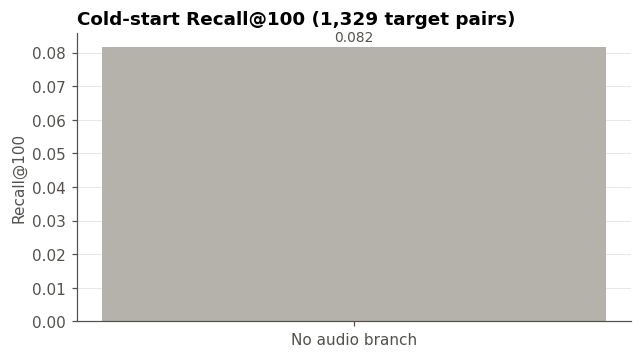

Audio comparison needs both the main and the no-audio results; only No audio branch available.


In [4]:
if not res:
    print('No ablation results available yet; section skipped.')
else:
    runs = list(res)
    vals = [res[r]['cold']['recall@100'] for r in runs]
    fig, ax = plt.subplots(figsize=(6.5, 3.4))
    b = ax.bar([VARIANTS[r] for r in runs], vals, color=[VAR_COLOR[r] for r in runs], width=0.55)
    bar_labels(ax, b, vals, fontsize=9)
    ax.set(ylabel='Recall@100', title=f"Cold-start Recall@100 ({res[runs[0]]['cold']['targets']:,} target pairs)")
    save(fig, '17_ablation_cold_start')
    if {'tt_AB', 'tt_AB_noaudio'} <= set(res):
        a, n = res['tt_AB'], res['tt_AB_noaudio']
        msg = (f"Audio branch: cold Recall@100 {a['cold']['recall@100']:.3f} with audio versus {n['cold']['recall@100']:.3f} without "
               f"({a['cold']['recall@100'] / n['cold']['recall@100'] - 1:+.0%}); discovery Recall@100 changes "
               f"{a['discovery']['recall@100'] / n['discovery']['recall@100'] - 1:+.0%} and all-view NDCG@10 "
               f"{a['all']['ndcg@10'] / n['all']['ndcg@10'] - 1:+.0%}.")
        print(msg); notes.append(msg)
    else:
        print('Audio comparison needs both the main and the no-audio results; only ' + ', '.join(VARIANTS[r] for r in runs) + ' available.')

## 3. Hard negatives on and off

Hard negatives are tracks the current model already scores highly for a user but that the user never played; they are re-mined every 1,000 steps and added to the in-batch negatives. The chart compares the main model with the variant trained on in-batch negatives only.

In [5]:
if not {'tt_AB', 'tt_AB_nohn'} <= set(res):
    print('Hard-negative comparison needs results/tt_tt_AB.json and results/tt_tt_AB_nohn.json; section skipped.')
else:
    on, off = res['tt_AB'], res['tt_AB_nohn']
    fig, ax = plt.subplots(figsize=(9, 3.4))
    x, w = np.arange(len(COLS)), 0.38
    for j, (r, d) in enumerate([('tt_AB_nohn', off), ('tt_AB', on)]):
        vals = [d[v][m] for v, m in COLS]
        b = ax.bar(x + (j - 0.5) * w, vals, w, color=VAR_COLOR[r], label='In-batch + hard negatives' if r == 'tt_AB' else 'In-batch only')
        bar_labels(ax, b, vals)
    ax.set_xticks(x, [c.replace(' ', '\n', 1) for c in COLS.values()]); ax.legend(loc='upper right'); ax.set_title('Effect of hard negatives')
    save(fig, '18_ablation_hard_negatives')
    delta = ', '.join(f'{lbl} {on[v][m] / off[v][m] - 1:+.0%}' for (v, m), lbl in COLS.items())
    msg = f'Hard negatives versus in-batch only: {delta}.'
    if 'tt_AB' in cfg:
        msg += f" Mining took {cfg['tt_AB']['mining_time_s']:.0f} s of {cfg['tt_AB']['wall_time_s'] / 60:.0f} min of training."
    print(msg); notes.append(msg)

Hard-negative comparison needs results/tt_tt_AB.json and results/tt_tt_AB_nohn.json; section skipped.


## Summary

Bullet points below are computed from the result files in the cells above.

In [6]:
display(Markdown('\n'.join(f'- {n}' for n in notes) if notes else '- No result files were available when this notebook ran.'))

- No audio branch: discovery Recall@100 0.113, cold Recall@100 0.082.